In [17]:
from src.InverseHeatModel import InverseHeatModel
from src.print_utils import print_kv, print_section

import torch
import h5py
import matplotlib.pyplot as plt

import numpy as np
import torch
import torch.nn as nn

plt.style.use("styles/plots.mplstyle")

In [18]:
def make_windows(g: torch.Tensor, f: torch.Tensor, W: int) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Split each sample into non-overlapping windows of size W.

    The last `n_timesteps % W` samples are discarded if
    `n_timesteps` is not divisible by `W`.

    Args:
        g (np.ndarray):
            Input array with shape (n_samples, n_timesteps).

        f (np.ndarray):
            Target array with shape (n_samples, n_timesteps).

        W (int):
            Window length in samples.

    Returns:
        tuple[np.ndarray, np.ndarray]:
            - g_wins: Array with shape (n_samples, n_windows, W).
            - f_wins: Array with shape (n_samples, n_windows, W).
    """
    
    n_samples, n_timesteps = g.shape
    n_windows = n_timesteps // W
 
    g_wins = g[:, : n_windows * W].reshape(n_samples, n_windows, W)
    f_wins = f[:, : n_windows * W].reshape(n_samples, n_windows, W)
 
    return g_wins, f_wins


In [ ]:
def train(
    model,
    g_tr_wins:  torch.Tensor,
    f_tr_wins:  torch.Tensor,
    g_va_wins:  torch.Tensor,
    f_va_wins:  torch.Tensor,
    n_epochs:           int   = 2000,
    lr:                 float = 1e-3,
    weight_decay:       float = 0.0,
    checkpoint_path:    str   = "assets/tikhonov_learned/best_tikhonov.pt",
    log_every:          int   = 100,
    save_every:         int   = 100,
    history: dict[str, list] = None 
       
) -> dict:
    """
    Training loop with non-overlapping windows.

    Args:
        model (InverseHeatModel):
            Model to train.

        g_tr_wins (np.ndarray):
            Training input windows with shape
            (n_samples, n_windows, W).

        f_tr_wins (np.ndarray):
            Training target windows with shape
            (n_samples, n_windows, W).

        g_va_wins (np.ndarray):
            Validation input windows with shape
            (n_samples, n_windows, W).

        f_va_wins (np.ndarray):
            Validation target windows with shape
            (n_samples, n_windows, W).

    Returns:
        dict[str, list[float]]:
            Dictionary containing:
                - "train_loss": training loss history
                - "val_loss": validation loss history
                - "lr": learning rate history
    """
    
    _, _, W = g_tr_wins.shape
    
    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=2000, T_mult=2, eta_min=1e-6
    )
    loss_fn = nn.MSELoss()
    
    if history is None:
        history     = {"train_loss": [], "val_loss": [], "lr": []}
    
    best_val    = float("inf")
        
    print_section("Training")
    for epoch in range(1, n_epochs + 1):
 
        # Training step                                                       
        model.train()
        optimizer.zero_grad()
 
        loss_train = _windowed_loss(model, g_tr_wins, f_tr_wins, loss_fn)
 
        loss_train.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
 
        # Validation step                                                     
        model.eval()
        with torch.no_grad():
            loss_val = _windowed_loss(model, g_va_wins, f_va_wins, loss_fn)
 
        train_l = loss_train.item()
        val_l   = loss_val.item()
 
        scheduler.step(val_l)
        current_lr = optimizer.param_groups[0]["lr"]
 
        history["train_loss"].append(train_l)
        history["val_loss"].append(val_l)
        history["lr"].append(current_lr)

        # Save checkpoint if the current validation loss is less then the previous one.
        # In this case update the min validation loss
        if epoch % save_every == 0:
            if val_l < best_val:
                best_val = val_l
                torch.save(
                    {
                        "epoch":           epoch,
                        "model_state":     model.state_dict(),
                        "optimizer_state": optimizer.state_dict(),
                        "val_loss":        best_val,
                        "W":               W,
                    },
                    checkpoint_path,
                )
 
        if epoch % log_every == 0 or epoch == 1:
            print(
                f"Epoch {epoch:5d}/{n_epochs} | "
                f"train MSE: {train_l:.2e} | "
                f"val MSE: {val_l:.2e} | "
                f"lr: {current_lr:.2e}"
            )
 
    print(f"\nBest val MSE: {best_val:.2e} -> {checkpoint_path}")
    return history
 
 
def _windowed_loss(model: InverseHeatModel, g_wins: torch.Tensor, f_wins: torch.Tensor, loss_fn) -> float:
    """
    Compute the mean loss over all windows and samples.

    For each sequence of windows, the current sample is reconstructed
    using the previous `g` window as `g_prev`.

    The first window of each sample is excluded from the loss computation
    because `g_prev = 0` by definition. This assumes the system starts
    in thermal equilibrium with the environment (e.g. T = 0 for all x).

    Args:
        g_wins (np.ndarray):
            Input windows with shape (n_samples, n_windows, W).

        f_wins (np.ndarray):
            Target windows with shape (n_samples, n_windows, W).

    Returns:
        float:
            Mean loss over all samples and valid windows.
    """
    
    n_samples, n_windows, W = g_wins.shape
    device = g_wins.device
 
    preds = [] 
 
    for i_win in range(n_windows):
        g_cur = g_wins[:, i_win, :]             # (n_samples, W)
 
        if i_win == 0:
            # First windows: g_prev = zero
            g_prev = torch.zeros_like(g_cur)
        else:
            g_prev = g_wins[:, i_win - 1, :]    # (n_samples, W)
 
        f_pred = model(g_cur, g_prev)           # (n_samples, W)
        preds.append(f_pred)

    preds = torch.stack(preds, dim=1)           # (n_samples, n_windows, W)
    
    return loss_fn(preds, f_wins)

# Dataset Loading

In [20]:
DATASET_CODE    = "w50/"
H5_PATH         =  f"dataset/{DATASET_CODE}dataset.h5"
M               = 0                   
W               = 200                
VAL_FRACTION    = 0.1
SEED            = 42

In [21]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print_kv("Device", f"{device}")

Device                                                            cuda


In [22]:
# --- Load simulation parameters --------
L, Tf, nt, D, h_param, l, _, r, _ = np.loadtxt(
    f"dataset/{DATASET_CODE}simulation_info.csv", delimiter=";", usecols=1
)

nt = int(nt)            # Number of time samples
dt = Tf / nt            # Sampling time interval

nk  = int(2 * W - 1)    # Number of discrete frequencies in a windows
n_windows = nt // W     # Number of windows
tau = int(L*L/D/dt)


print_kv("L         [m]"        , f"{L}")
print_kv("Tf        [sec]"      , f"{Tf}")
print_kv("D"                    , f"{D}")
print_kv("Tau       [sample]"   , f"{tau}")
print_kv("W         [sample]"   , f"{W}")
print_kv("n_windows"            , f"{n_windows}")
print_kv("nt"                   , f"{nt}")
print_kv("dt        [sec]"      , f"{dt}")
print_kv("nk"                   , f"{nk}")

L         [m]                                                      1.0
Tf        [sec]                                                   30.0
D                                                                  1.0
Tau       [sample]                                                 333
W         [sample]                                                 200
n_windows                                                           50
nt                                                               10000
dt        [sec]                                                  0.003
nk                                                                 399


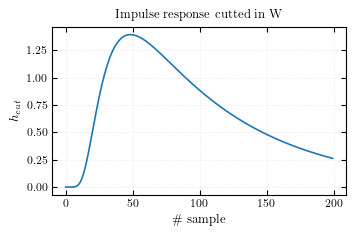

In [23]:
# --- Load impulse response --------------
h       = np.loadtxt( f"dataset/{DATASET_CODE}impulse_response.csv", delimiter=";")
h_cut   = h[:W]
H       = np.fft.rfft(h_cut, nk).astype(np.complex64)
freqs   = np.fft.rfftfreq(nk, d=dt)
omegas  = freqs * 2 * np.pi

# --- Cut the impulse response into the window
# The impulse response should be negligible before the end of the window
plt.plot(h_cut)
plt.xlabel("\# sample")
plt.ylabel(r"$h_{cut}$")
plt.title("Impulse response cutted in W")
plt.grid()
plt.show()

In [24]:
# ---- Load dataset ----------------------

with h5py.File(H5_PATH, "r") as hf:
    data = hf["dataset"][:]              # (N, 2, nt)

f_all = data[:, 0, :].astype(np.float32)
g_all = data[:, 1, :].astype(np.float32)

# --- Validation and trainign set declaration --------

N = len(f_all)

rng       = np.random.default_rng(SEED)
idx       = rng.permutation(N)
n_val     = max(1, int(VAL_FRACTION * N))
idx_val   = idx[:n_val]
idx_train = idx[n_val:]

g_train = torch.from_numpy(g_all[idx_train]).to(device)
f_train = torch.from_numpy(f_all[idx_train]).to(device)
g_val   = torch.from_numpy(g_all[idx_val]).to(device)
f_val   = torch.from_numpy(f_all[idx_val]).to(device)

In [25]:
# Divide the dataset into windows. This is performed only once here.
# Shape: (n_samples, n_timesteps) -> (n_samples, n_windows, W)
g_tr_wins, f_tr_wins = make_windows(g_train ,f_train   ,W)
g_va_wins, f_va_wins = make_windows(g_val   ,f_val     ,W)

n_samples_tr    ,n_windows_tr  ,_ = g_tr_wins.shape
n_samples_val   ,n_windows_val ,_ = g_va_wins.shape

print_section("Training Dataset")

print_kv("n_samples"                , f"{n_samples_tr}")
print_kv("n_windows per sample"     , f"{n_windows_tr}")
print_kv("tot windows"              , f"{n_samples_tr*n_windows_tr}")

print_section("validation Dataset")

print_kv("n_samples"                  , f"{n_samples_val}")
print_kv("n_windows per sample"       , f"{n_windows_val}")
print_kv("tot windows"                , f"{n_samples_val*n_windows_val}")


---------------------------Training Dataset---------------------------

n_samples                                                          270
n_windows per sample                                                50
tot windows                                                      13500

--------------------------validation Dataset--------------------------

n_samples                                                           30
n_windows per sample                                                50
tot windows                                                       1500


# Model Initialization

In [26]:
model = InverseHeatModel(H=H, nt=W, dt=dt, M=M).to(device)

# Load pretrained model
LOAD_LOCATION = "assets/tikhonov_learned/w50/best_tikhonov.pt"
PRELOAD_MODEL = False

if LOAD_LOCATION != None and PRELOAD_MODEL == True:
    ckpt = torch.load(LOAD_LOCATION, map_location="cpu")
    model.load_state_dict(ckpt["model_state"])
    model.to(device)
    print_kv("Model preloaded", LOAD_LOCATION)

n_params = sum(p.numel() for p in model.parameters())

print(model)

InverseHeatModel(
  nt                      =   200,
  nk                      =   200,
  n                       =   399,
  dt                      =   0.003,
  sigma_bandwidth         =   0,
  sigma_parameters        =   200,
  total_parameters        =   600,
  trainable_parameters    =   600
)


In [27]:
@torch.no_grad()
def predict(model, g: torch.Tensor, W: int) -> torch.Tensor:
    """
    Reconstruct a full signal from sequential window predictions.

    The input signal is divided into windows of size `W`, and each
    window is reconstructed sequentially using the previously
    reconstructed window as context.

    Args:
        g (np.ndarray):
            Input signal with shape (n_timesteps,) or
            (n_samples, n_timesteps).

        W (int):
            Window length. Must match the value used during training.

    Returns:
        np.ndarray:
            Reconstructed signal with the same shape as `g`.
    """
    
    squeeze = g.dim() == 1
    if squeeze:
        g = g.unsqueeze(0)   # (1, T)
 
    n_samples, T    = g.shape
    n_windows       = T // W
    g_trim          = g[:, : n_windows * W]

    g_wins          = g_trim.reshape(n_samples, n_windows, W)
    preds           = []
 
    for i_win in range(n_windows):
        g_cur  = g_wins[:, i_win, :]
        g_prev = g_wins[:, i_win - 1, :] if i_win > 0 else torch.zeros_like(g_cur)
        preds.append(model(g_cur, g_prev))
 
    f_pred = torch.cat(preds, dim=-1)   # (n_samples, n_windows * W)
 
    return f_pred.squeeze(0) if squeeze else f_pred

In [28]:
def predictions_plot(
    g_val       : torch.Tensor, 
    f_val       : torch.Tensor,
    W           : int, 
    n_plots     : int = 6,
    ncols       : int = 2,
    max_window  : int = 7,
    min_window  : int = 0,
    save_path   : str   = None,
    max_y       : float = 3,
    min_y       : float = -3,
    loss_function = nn.MSELoss()
    ):
    
    max_index = max_window*W
    min_index = min_window*W

    nrows = int(np.ceil(n_plots / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(14, 3 * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=False
    )

    axes = np.array(axes).reshape(-1)

    g_test_w, f_test_w = make_windows(g_val,f_val,W)
    
    for index in range(n_plots):
        
        loss_windows_array = []
        
        g_test = g_val[index][:max_index]
        f_test = f_val[index][:max_index]
        f_pred = predict(model,g_test,W)
         
        loss = _windowed_loss(model, g_test_w[[index],:,:], f_test_w[[index],:,:], loss_function)
            
        #for j in range(n_windows):
            #loss_windows_array.append(loss_function(g_test_w[[index],[j],:], f_pred[j*W:(j+1)*W]))
            
        ax = axes[index]
        
        ax.plot(g_test.cpu().numpy(), label=r"$g$",        c="k")
        ax.plot(f_test.cpu().numpy(), label=r"$f_{true}$", c="b", lw=4,  alpha =0.5)
        ax.plot(f_pred.cpu().numpy(), label=r"$f_{rec}$",  c="r")
        
        # Plot windows separation and windows number
        for j in range(n_windows + 1):
                
            ax.axvline(W*j, c="k", ls="-.", alpha =0.8, lw=1)
            
            if W*j >= min_index and W*j < max_index:
                ax.text(W*(j+0.5),2,
                        j,
                        ha="center",
                        va="center",
                        bbox=dict(
                            boxstyle="square,pad=0.3",
                            facecolor="white",
                            edgecolor="black",
                            linewidth=1
                        ))
                #ax.text(W*(j+0.5),min_y -1,f"W_MSE\n{loss_windows_array[j]:.2e}",ha="center",va="center")
            
        ax.set_xlim([min_index, max_index])
        ax.set_ylim([min_y, max_y])
        ax.set_title(f"Sample {index}, MSE: {loss:.2e}")
        ax.grid()
        
    # Hide subplot not used
    for k in range(n_plots, len(axes)):
        axes[k].axis("off")

    # Only one legend
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=3
    )

    fig.supxlabel("time sample")
    fig.supylabel("signal amplitude")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    if save_path is not None:
        plt.savefig(save_path)
    
    plt.show()

# Training

In [29]:
history = None
DO_TRAINING = True

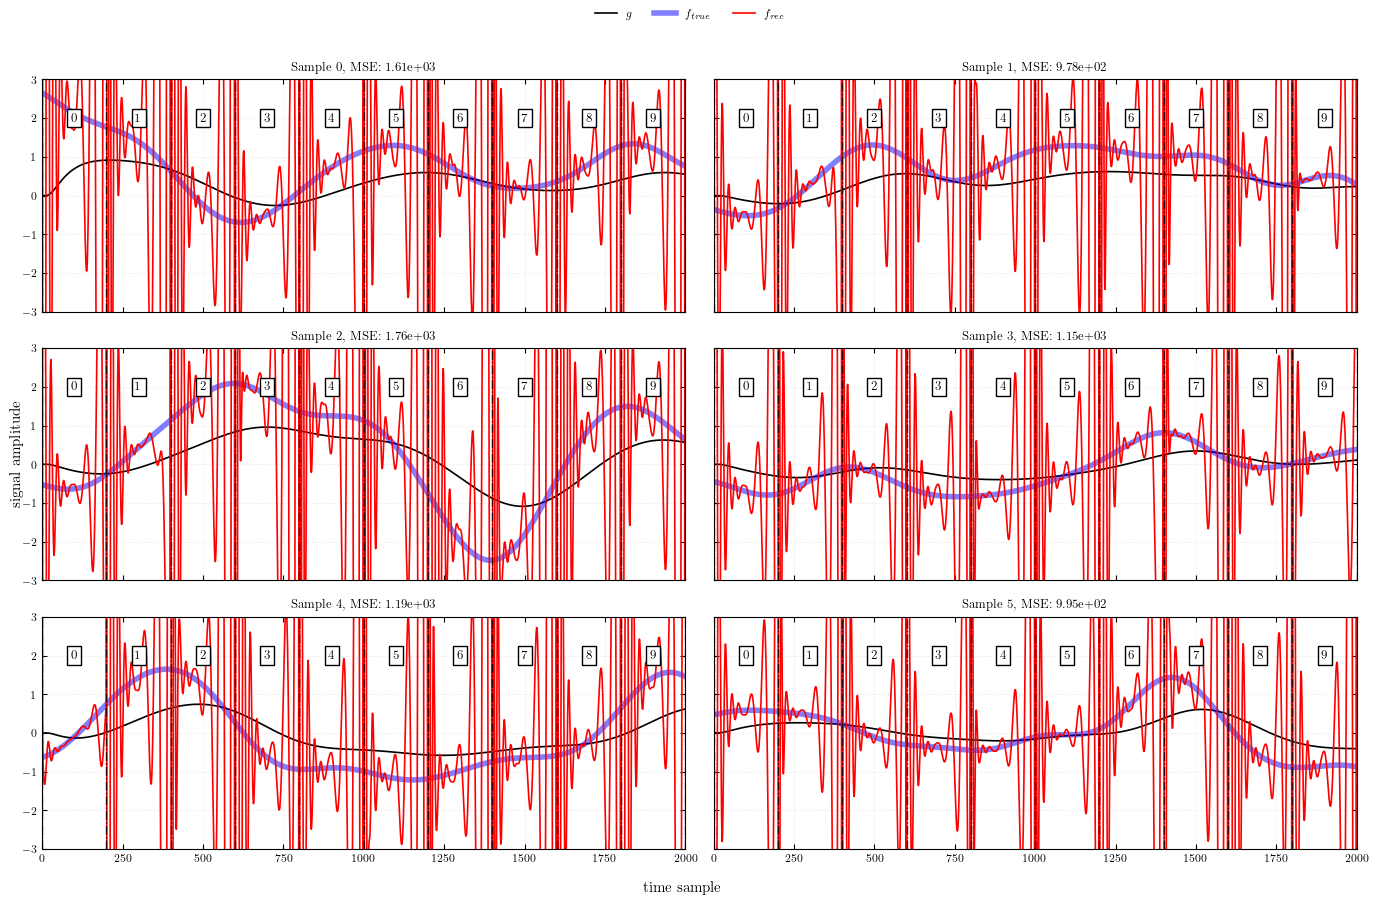

In [30]:
predictions_plot(g_val, f_val, W = W,max_window=10)

## R-Phi training

Only train $R$ and $\phi$ on the first window where g_prev = 0 and the system is LTI

OSSERVAZIONE: se traino su 20000 epoche la prima fase poi il modello NON riesce a genralizzare per le finestre successive, o almeno non nello stesso tempo che se uso 10000 epoche

InverseHeatModel(
  nt                      =   200,
  nk                      =   200,
  n                       =   399,
  dt                      =   0.003,
  sigma_bandwidth         =   0,
  sigma_parameters        =   200,
  total_parameters        =   600,
  trainable_parameters    =   400
)

-------------------------------Training-------------------------------

Epoch     1/5000 | train MSE: 2.5740e+02 | val MSE: 2.8081e+02 | lr: 9.52e-04
Epoch  1000/5000 | train MSE: 1.9035e+01 | val MSE: 2.0609e+01 | lr: 1.00e-03
Epoch  2000/5000 | train MSE: 1.5286e-01 | val MSE: 1.5397e-01 | lr: 1.00e-03
Epoch  3000/5000 | train MSE: 7.3694e-02 | val MSE: 7.3441e-02 | lr: 1.00e-03
Epoch  4000/5000 | train MSE: 6.6450e-02 | val MSE: 6.6079e-02 | lr: 1.00e-03
Epoch  5000/5000 | train MSE: 6.3447e-02 | val MSE: 6.1996e-02 | lr: 1.00e-03

Best val MSE: 6.1996e-02 -> assets/tikhonov_learned/w50/best_tikhonov.pt


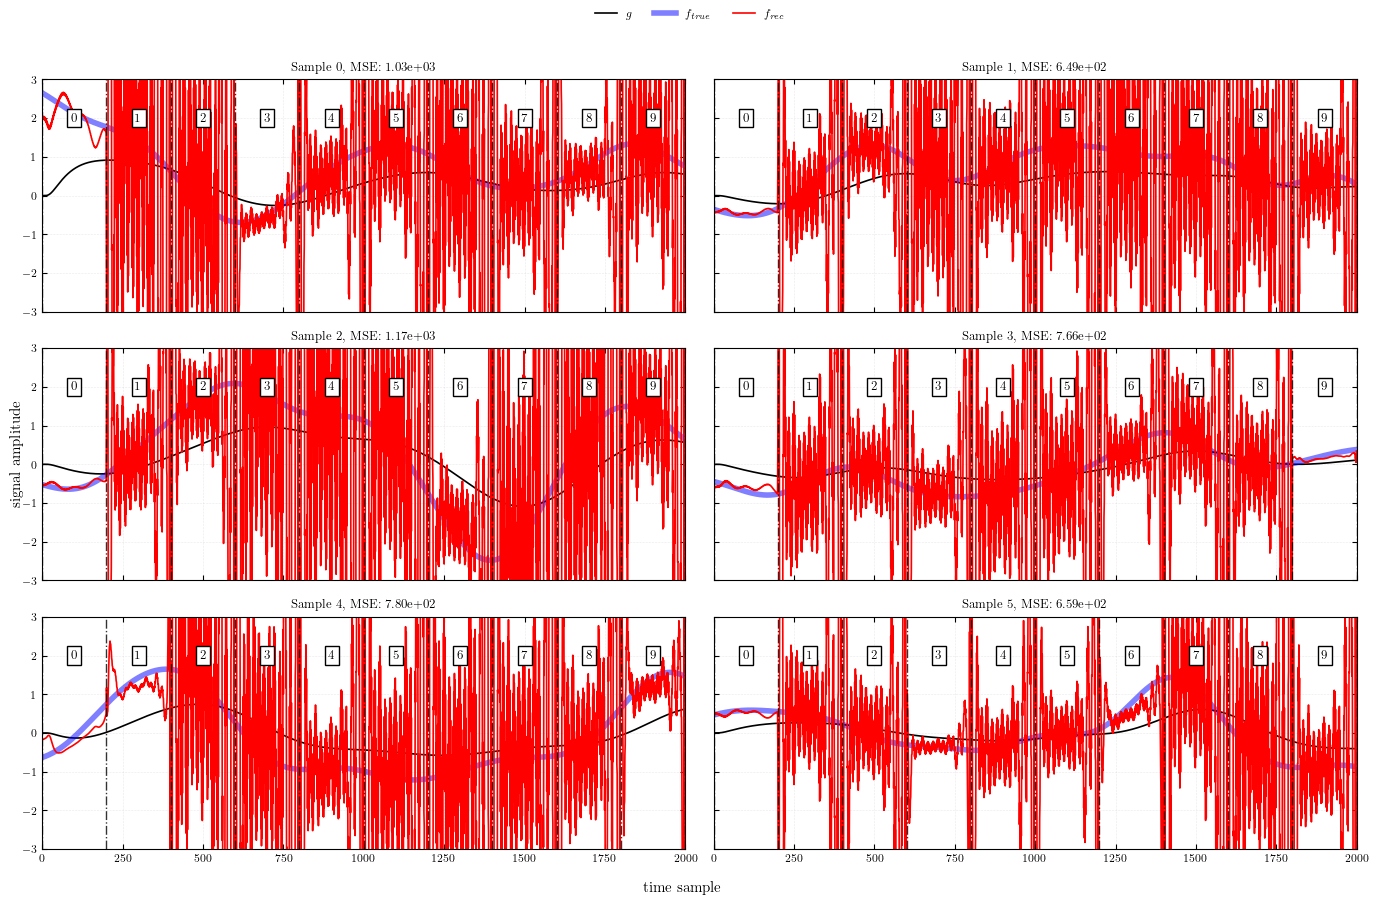

In [31]:
if DO_TRAINING:
    
    model.freeze_all()
    model.unfreeze_phi()
    model.unfreeze_R()
    
    history = train(
        model        = model,
        g_tr_wins    = g_tr_wins[:,[0],:],
        f_tr_wins    = f_tr_wins[:,[0],:],
        g_va_wins    = g_va_wins[:,[0],:],
        f_va_wins    = f_va_wins[:,[0],:],
        n_epochs     = 5000,
        checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
        log_every    = 1000
    )
    
predictions_plot(g_val, f_val, W = W,max_window=10)

## Sigma training

In [ ]:
if DO_TRAINING:
    
    
    max_M = 5
    
    for m_index in range(max_M):
        
        model = model.sigma.increase_bandwidth(model, m_index)
        model.sigma.summary()
        
        history = train(
            model        = model,
            g_tr_wins    = g_tr_wins,
            f_tr_wins    = f_tr_wins,
            g_va_wins    = g_va_wins,
            f_va_wins    = f_va_wins,
            n_epochs     = 1000,
            checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt"
        )

predictions_plot(g_val, f_val, W = W, max_window=10)

----------------------------------------------------------------------
BandedSigma                                                nk=200  M=0
----------------------------------------------------------------------
Total Parameters                                                   200
Trainable                                                          200
Frozen                                                               0
----------------------------------------------------------------------
Diagonal                                                         Learn
----------------------------------------------------------------------
Non-zero elements                                           200/40,000
Sparsity                                                         99.5%
----------------------------------------------------------------------

-------------------------------Training-------------------------------

Epoch     1/1000 | train MSE: 8.2779e+02 | val MSE: 8.1591e+02 | lr: 6.43e-

In [ ]:
if DO_TRAINING:
    
    model.freeze_all()
    model.unfreeze_phi()
    model.unfreeze_R()
    
    print(model)
    
    history = train(
        model        = model,
        g_tr_wins    = g_tr_wins[:,:,:],
        f_tr_wins    = f_tr_wins[:,:,:],
        g_va_wins    = g_va_wins[:,:,:],
        f_va_wins    = f_va_wins[:,:,:],
        n_epochs     = 1000,
        checkpoint_path = f"assets/tikhonov_learned/{DATASET_CODE}best_tikhonov.pt",
        log_every    = 1000
    )
    
predictions_plot(g_val, f_val, W = W,max_window=10)

In [ ]:
def plot_diagnostics(model, omegas: np.ndarray):
    
    fig, axes = plt.subplots(3, 1, figsize=(3.2, 3.6), sharex=True)

    ax1, ax2, ax3 = axes
    
    # Phi Plot
    ax1.plot(omegas, np.degrees(model.get_phi()), color="steelblue", lw=1.5)
    ax1.axhline(0, color="k", lw=0.2, ls="--")
    ax1.set_ylabel(r"$\phi_\theta$")
    ax1.set_title(r"Learned model $W_\theta$")
    ax1.grid(True)
    
    # R plot
    ax2.semilogy(omegas, model.get_R(), color="darkorange", lw=1)
    ax2.set_ylabel(r"$R_\theta$")
    ax2.set_title("")
    ax2.grid(True)

    # W plot
    ax3.semilogy(omegas, model.get_W_magnitude(), color="r", lw=1, label=r"Learned $|W_\theta|$")
        
    ax3.set_ylabel(r"$|W|$")
    ax3.set_xlabel(r"$\omega$")
    ax3.set_title("")
    ax3.legend()
    ax3.grid(True)

    plt.show()
    
def plot_history(history: dict):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots()
    
    ax.semilogy(epochs, history["train_loss"], label="Train MSE")
    ax.semilogy(epochs, history["val_loss"],   label="Val MSE", ls="--")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_title("Loss curve")
    ax.legend()
    ax.grid(True)
    plt.show()

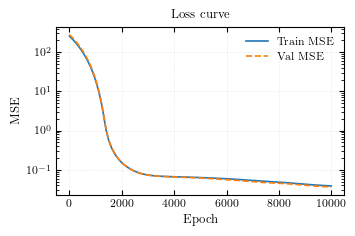

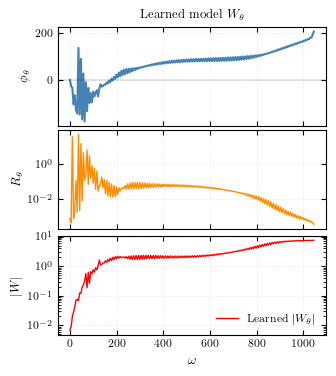

In [ ]:
if history is not None:
    plot_history(history=history)

plot_diagnostics(model=model, omegas=omegas)